<a href="https://colab.research.google.com/github/SeoulTechPSE/tong_lectures/blob/main/2_quantum/topics_in_qm/aqm_ch02_figures.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

*Topics in Quantum Mechanics* — `aqm_ch02_figures.ipynb` · after D. Tong's Cambridge lecture notes · Kee-Youn Yoo, Process Systems Laboratory, SeoulTech

# AQM Chapter 2 — Band Structure Figures
Run in Colab. Last cell auto-downloads a ZIP of all figures.

In [1]:

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import Polygon
from mpl_toolkits.mplot3d.art3d import Poly3DCollection
from scipy.spatial import ConvexHull
import os

plt.rcParams.update({
    'figure.facecolor': '#1e1e2e', 'axes.facecolor': '#1e1e2e',
    'text.color': '#cdd6f4', 'axes.labelcolor': '#cdd6f4',
    'xtick.color': '#cdd6f4', 'ytick.color': '#cdd6f4',
    'axes.edgecolor': '#45475a', 'grid.color': '#313244',
    'font.family': 'DejaVu Sans', 'font.size': 12,
    'axes.titlesize': 13, 'axes.titleweight': 'bold',
    'mathtext.fontset': 'cm',
})
BLUE='#7ec8e3'; YELLOW='#f9c74f'; GREEN='#90ee90'
RED='#e07070';  PURPLE='#c792ea'; ORANGE='#ffb347'; BG='#1e1e2e'
os.makedirs('figures/ch02', exist_ok=True)
SAVE = lambda n: plt.savefig(f'figures/ch02/{n}', dpi=150,
                              bbox_inches='tight', facecolor=BG)
print('Setup complete.')


Setup complete.


## Fig 01 — 1D Tight-Binding Dispersion

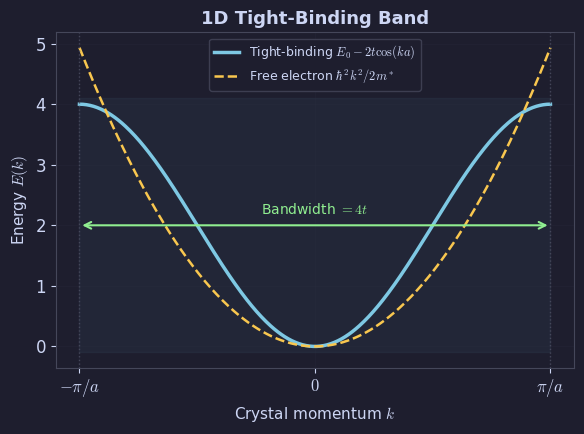

Fig 01 saved.


In [2]:

# Fig 01: 1D tight-binding + free-electron parabola
a=1.; t=1.; E0=2.
k = np.linspace(-np.pi/a, np.pi/a, 400)
E_tb   = E0 - 2*t*np.cos(k*a)
E_free = k**2/2 + (E0-2*t)

fig, ax = plt.subplots(figsize=(6,4.5))
ax.plot(k, E_tb,   color=BLUE,   lw=2.5, label=r'Tight-binding $E_0-2t\cos(ka)$')
ax.plot(k, E_free, color=YELLOW, lw=1.8, ls='--', label=r'Free electron $\hbar^2k^2/2m^*$')
for xb in [-np.pi/a, np.pi/a]:
    ax.axvline(xb, color='#45475a', lw=1., ls=':')
ax.fill_betweenx([E0-2*t-.1, E0+2*t+.1], -np.pi/a, np.pi/a, color=BLUE, alpha=.05)
ax.annotate('', xy=(np.pi/a, E0), xytext=(-np.pi/a, E0),
            arrowprops=dict(arrowstyle='<->', color=GREEN, lw=1.5))
ax.text(0, E0+.18, 'Bandwidth $= 4t$', color=GREEN, ha='center', fontsize=10)
ax.set_xlabel(r'Crystal momentum $k$', fontsize=11)
ax.set_ylabel(r'Energy $E(k)$', fontsize=11)
ax.set_title('1D Tight-Binding Band', color='#cdd6f4')
ax.set_xticks([-np.pi/a, 0, np.pi/a])
ax.set_xticklabels([r'$-\pi/a$','$0$',r'$\pi/a$'])
ax.legend(fontsize=9, facecolor=BG, edgecolor='#45475a', labelcolor='#cdd6f4', loc='upper center')
ax.grid(True, alpha=.2)
plt.tight_layout(); SAVE('fig01_tight_binding_1d.png'); plt.show()
print('Fig 01 saved.')


## Fig 02 — Metal vs Band Insulator

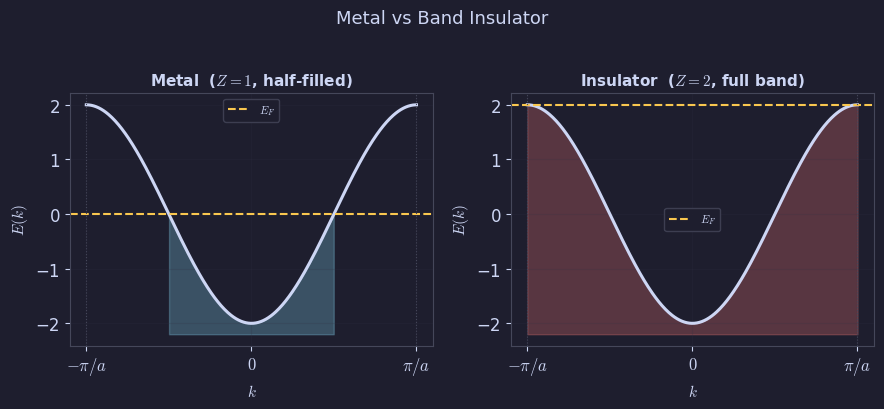

Fig 02 saved.


In [3]:

# Fig 02: Metal (half-filled) vs Insulator (full band)
a=1.; t=1.; E0=0.
k = np.linspace(-np.pi/a, np.pi/a, 400)
E = E0 - 2*t*np.cos(k*a)
fig, axes = plt.subplots(1,2,figsize=(9,4))
for ax, (kF, title, col) in zip(axes,[
        (np.pi/(2*a), 'Metal  ($Z=1$, half-filled)', BLUE),
        (np.pi/a,     'Insulator  ($Z=2$, full band)', RED)]):
    ax.plot(k, E, color='#cdd6f4', lw=2.2)
    ax.fill_between(k, E.min()-.2, E, where=(np.abs(k)<=kF+1e-9), color=col, alpha=.30)
    EF = E0 - 2*t*np.cos(kF*a)
    ax.axhline(EF, color=YELLOW, lw=1.5, ls='--', label='$E_F$')
    for xb in [-np.pi/a, np.pi/a]: ax.axvline(xb, color='#45475a', lw=.8, ls=':')
    ax.set_xlabel(r'$k$',fontsize=11); ax.set_ylabel(r'$E(k)$',fontsize=11)
    ax.set_title(title, color='#cdd6f4', fontsize=11)
    ax.set_xticks([-np.pi/a,0,np.pi/a])
    ax.set_xticklabels([r'$-\pi/a$','$0$',r'$\pi/a$'])
    ax.legend(fontsize=8, facecolor=BG, edgecolor='#45475a', labelcolor='#cdd6f4')
    ax.grid(True, alpha=.2)
plt.suptitle('Metal vs Band Insulator', color='#cdd6f4', fontsize=13, y=1.02)
plt.tight_layout(); SAVE('fig02_metal_insulator.png'); plt.show()
print('Fig 02 saved.')


## Fig 03 — Nearly-Free Electron Bands (1D)

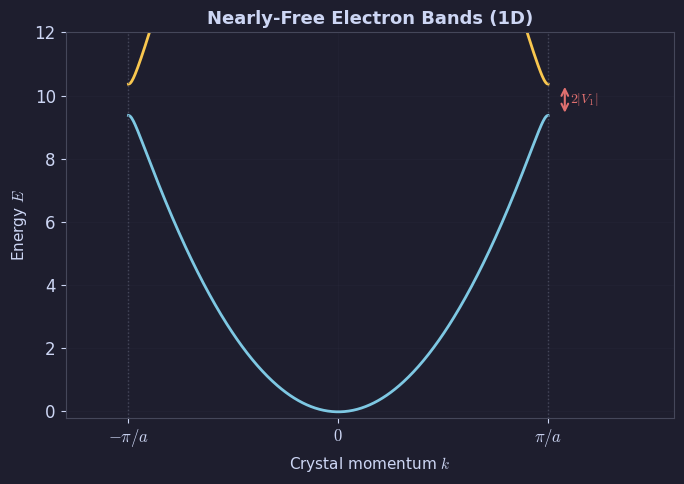

Fig 03 saved.


In [4]:

# Fig 03: Nearly-free electron 1D bands via matrix diagonalisation
a=1.; V1=0.5; V2=0.25; h2m=1.
k_bz = np.linspace(-np.pi/a, np.pi/a, 500)

def nfe_bands_1d(k_arr, n_G=4):
    Gs  = [n*2*np.pi/a for n in range(-n_G, n_G+1)]
    out = []
    for k in k_arr:
        H = np.diag([h2m*(k+g)**2 for g in Gs])
        for i in range(len(Gs)):
          for j in range(len(Gs)):
            diff = int(round((Gs[i]-Gs[j])*a/(2*np.pi)))
            if abs(diff)==1: H[i,j] += V1
            elif abs(diff)==2: H[i,j] += V2
        out.append(np.sort(np.linalg.eigvalsh(H)))
    return np.array(out)

Ek = nfe_bands_1d(k_bz)
cols = [BLUE,YELLOW,GREEN,RED,PURPLE,ORANGE]

fig, ax = plt.subplots(figsize=(7,5))
for b in range(min(5,Ek.shape[1])):
    ax.plot(k_bz, Ek[:,b], color=cols[b%len(cols)], lw=2.)
for xb in [-np.pi/a, np.pi/a]: ax.axvline(xb, color='#45475a', lw=1., ls=':')

# Gap annotation
idx = np.argmin(np.abs(k_bz - np.pi/a))
Ebot, Etop = Ek[idx,0], Ek[idx,1]
ax.annotate('', xy=(np.pi/a+.25, Etop), xytext=(np.pi/a+.25, Ebot),
            arrowprops=dict(arrowstyle='<->', color=RED, lw=1.5))
ax.text(np.pi/a+.33, (Etop+Ebot)/2, r'$2|V_1|$', color=RED, fontsize=10, va='center')
ax.set_xlabel(r'Crystal momentum $k$',fontsize=11)
ax.set_ylabel(r'Energy $E$',fontsize=11)
ax.set_title('Nearly-Free Electron Bands (1D)', color='#cdd6f4')
ax.set_xticks([-np.pi/a,0,np.pi/a]); ax.set_xticklabels([r'$-\pi/a$','$0$',r'$\pi/a$'])
ax.set_xlim(-1.3*np.pi/a, 1.6*np.pi/a); ax.set_ylim(-0.2, 12)
ax.grid(True, alpha=.2)
plt.tight_layout(); SAVE('fig03_nearly_free_1d.png'); plt.show()
print('Fig 03 saved.')


## Fig 04 — Floquet Matrix Trace

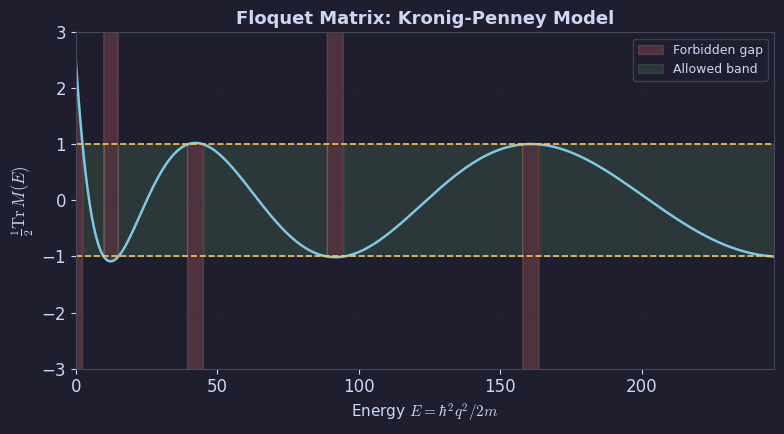

Fig 04 saved.


In [5]:

# Fig 04: Kronig-Penney Floquet (transfer matrix) trace
a=1.; lam=3.
q = np.linspace(0.05, 5*np.pi/a, 2000)
E = q**2
trace = np.cos(q*a) + (lam/(2*q))*np.sin(q*a)

fig, ax = plt.subplots(figsize=(8,4.5))
ax.plot(E, trace, color=BLUE, lw=1.8)
ax.axhline( 1, color=YELLOW, lw=1.2, ls='--')
ax.axhline(-1, color=YELLOW, lw=1.2, ls='--')
ax.fill_between(E,-3.5,trace, where=(trace>1),  color=RED,   alpha=.25, label='Forbidden gap')
ax.fill_between(E,trace,3.5,  where=(trace<-1), color=RED,   alpha=.25)
ax.fill_between(E,-1,1, where=(np.abs(trace)<=1), color=GREEN, alpha=.12, label='Allowed band')
ax.set_ylim(-3.,3.); ax.set_xlim(0,E.max())
ax.set_xlabel(r'Energy $E=\hbar^2q^2/2m$',fontsize=11)
ax.set_ylabel(r'$\frac{1}{2}\operatorname{Tr}M(E)$',fontsize=12)
ax.set_title('Floquet Matrix: Kronig-Penney Model', color='#cdd6f4')
ax.legend(fontsize=9, facecolor=BG, edgecolor='#45475a', labelcolor='#cdd6f4', loc='upper right')
ax.grid(True, alpha=.2)
plt.tight_layout(); SAVE('fig04_floquet_trace.png'); plt.show()
print('Fig 04 saved.')


## Fig 05 — Cubic Bravais Unit Cells

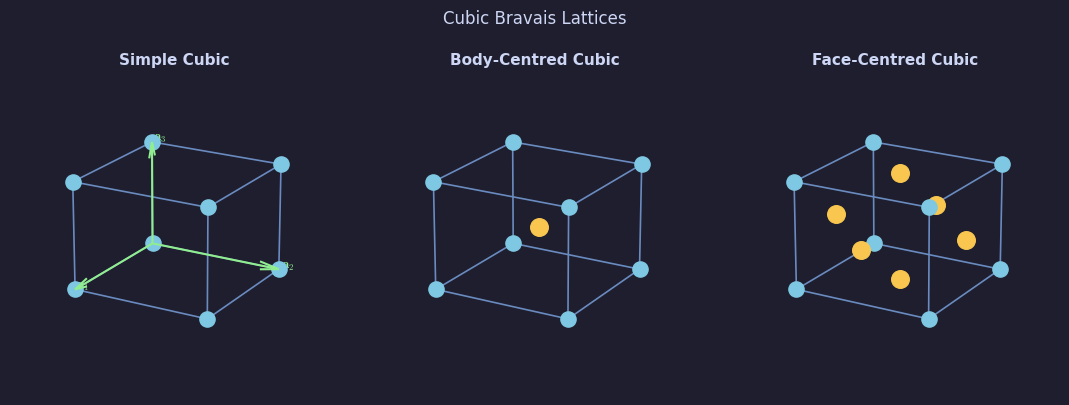

Fig 05 saved.


In [6]:

# Fig 05: SC / BCC / FCC unit cells
def cube_edges(ax, a, col='#6a8bbf', lw=1.2):
    pts = np.array([[i,j,k] for i in [0,a] for j in [0,a] for k in [0,a]])
    edgs = [(0,1),(0,2),(0,4),(1,3),(1,5),(2,3),(2,6),(3,7),(4,5),(4,6),(5,7),(6,7)]
    for e in edgs:
        ax.plot(*zip(pts[e[0]], pts[e[1]]), color=col, lw=lw)

fig = plt.figure(figsize=(11,4))
a = 1.
specs = [
    ('Simple Cubic',         []),
    ('Body-Centred Cubic',   [[.5,.5,.5]]),
    ('Face-Centred Cubic',   [[.5,.5,0],[.5,0,.5],[0,.5,.5],
                               [.5,.5,1],[.5,1,.5],[1,.5,.5]]),
]
for col,(name,extras) in enumerate(specs):
    ax = fig.add_subplot(1,3,col+1,projection='3d')
    ax.set_facecolor(BG)
    cube_edges(ax, a)
    for i in [0,1]:
      for j in [0,1]:
        for k in [0,1]:
          ax.scatter([i*a],[j*a],[k*a], color=BLUE, s=120, zorder=5, depthshade=False)
    for p in extras:
        ax.scatter([p[0]*a],[p[1]*a],[p[2]*a], color=YELLOW, s=160, zorder=6, depthshade=False)
    if col==0:
        for v,lbl in [([a,0,0],r'$\mathbf{a}_1$'),([0,a,0],r'$\mathbf{a}_2$'),([0,0,a],r'$\mathbf{a}_3$')]:
            ax.quiver(0,0,0,*v, color=GREEN, lw=1.5, arrow_length_ratio=.15)
            ax.text(v[0]+.05,v[1]+.05,v[2]+.05, lbl, color=GREEN, fontsize=9)
    ax.set_xlim(-.2,1.2); ax.set_ylim(-.2,1.2); ax.set_zlim(-.2,1.2)
    ax.set_axis_off()
    ax.set_title(name, color='#cdd6f4', pad=2, fontsize=11)
    ax.view_init(elev=20, azim=30)
plt.suptitle('Cubic Bravais Lattices', color='#cdd6f4', fontsize=12, y=1.01)
plt.tight_layout(); SAVE('fig05_bravais_cubic.png'); plt.show()
print('Fig 05 saved.')


## Fig 06 — Wigner-Seitz Cells

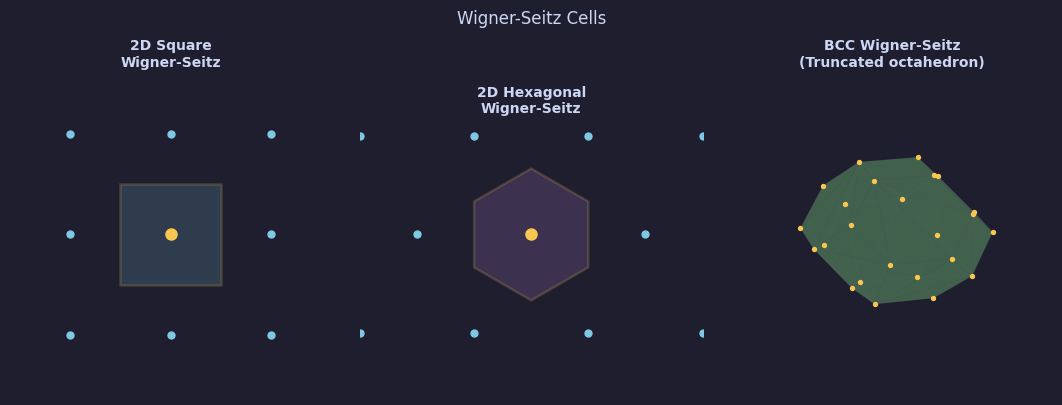

Fig 06 saved.


In [7]:

# Fig 06: Wigner-Seitz cells
fig = plt.figure(figsize=(11,4))

# 2D square
ax1 = fig.add_subplot(1,3,1)
ax1.set_facecolor(BG); ax1.set_aspect('equal')
a = 1.
for di in range(-2,3):
  for dj in range(-2,3):
    ax1.plot(di*a, dj*a, 'o', color=BLUE, ms=5, zorder=3)
ws = Polygon([[-a/2,-a/2],[a/2,-a/2],[a/2,a/2],[-a/2,a/2]],
              closed=True, fc=BLUE, alpha=.18, ec=YELLOW, lw=1.8, zorder=2)
ax1.add_patch(ws)
ax1.plot(0,0,'o',color=YELLOW,ms=8,zorder=5)
ax1.set_xlim(-1.6,1.6); ax1.set_ylim(-1.6,1.6)
ax1.set_title('2D Square\nWigner-Seitz', color='#cdd6f4', fontsize=10); ax1.axis('off')

# 2D hexagonal
ax2 = fig.add_subplot(1,3,2)
ax2.set_facecolor(BG); ax2.set_aspect('equal')
a1 = np.array([1.,0.]); a2 = np.array([.5,np.sqrt(3)/2])
for i in range(-2,3):
  for j in range(-2,3):
    pt = i*a1+j*a2; ax2.plot(*pt,'o',color=BLUE,ms=5,zorder=3)
ang = np.linspace(0,2*np.pi,7); r = 1./np.sqrt(3)
hx = r*np.cos(ang+np.pi/6); hy = r*np.sin(ang+np.pi/6)
ws2 = Polygon(list(zip(hx,hy)), closed=True, fc=PURPLE, alpha=.18, ec=YELLOW, lw=1.8, zorder=2)
ax2.add_patch(ws2)
ax2.plot(0,0,'o',color=YELLOW,ms=8,zorder=5)
ax2.set_xlim(-1.5,1.5); ax2.set_ylim(-1.0,1.0)
ax2.set_title('2D Hexagonal\nWigner-Seitz', color='#cdd6f4', fontsize=10); ax2.axis('off')

# 3D BCC W-S (truncated octahedron)
ax3 = fig.add_subplot(1,3,3,projection='3d')
ax3.set_facecolor(BG)
from itertools import permutations as iperms
verts_raw = set()
for s1,s2,s3 in [(a,b,c) for a in [1,-1] for b in [1,-1] for c in [1,-1]]:
    for perm in iperms([0,1,2]):
        verts_raw.add((s1*perm[0], s2*perm[1], s3*perm[2]))
verts = np.array(list(verts_raw), dtype=float)/2.
hull  = ConvexHull(verts)
faces = [verts[s] for s in hull.simplices]
poly  = Poly3DCollection(faces, alpha=.18, facecolor=GREEN, edgecolor='#45475a', lw=.5)
ax3.add_collection3d(poly)
ax3.scatter(*verts.T, color=YELLOW, s=8, zorder=5, depthshade=False)
ax3.set_xlim(-1.2,1.2); ax3.set_ylim(-1.2,1.2); ax3.set_zlim(-1.2,1.2)
ax3.set_axis_off()
ax3.set_title('BCC Wigner-Seitz\n(Truncated octahedron)', color='#cdd6f4', fontsize=10)
ax3.view_init(elev=20, azim=30)

plt.suptitle('Wigner-Seitz Cells', color='#cdd6f4', fontsize=12, y=1.01)
plt.tight_layout(); SAVE('fig06_wigner_seitz.png'); plt.show()
print('Fig 06 saved.')


## Fig 07 — First Brillouin Zones

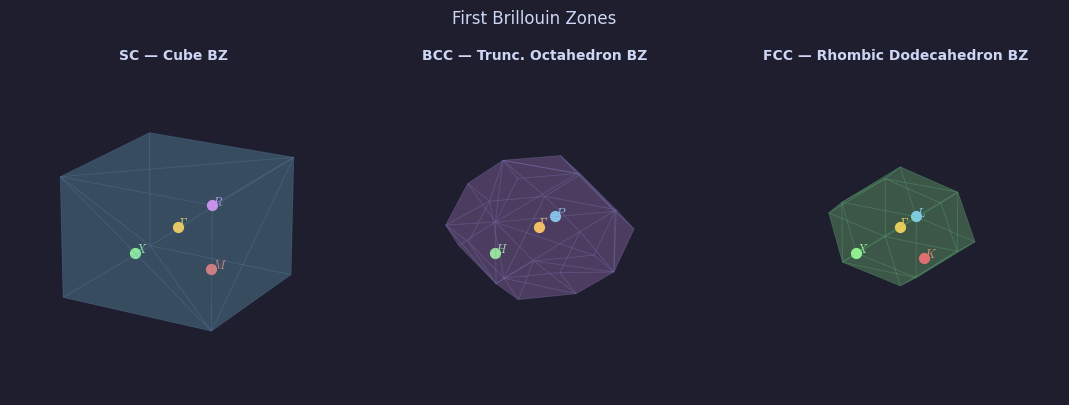

Fig 07 saved.


In [8]:

# Fig 07: 1st Brillouin zones (SC / BCC / FCC)
fig = plt.figure(figsize=(11,4))

def bz_hull_plot(ax, verts, facecolor, edgecolor, title, sym_pts):
    try:
        hull = ConvexHull(verts)
        for s in hull.simplices:
            tri = verts[s]
            poly = Poly3DCollection([tri], alpha=.15, facecolor=facecolor, edgecolor=edgecolor, lw=.6)
            ax.add_collection3d(poly)
    except Exception:
        pass
    for pt,lbl,col in sym_pts:
        ax.scatter(*pt, color=col, s=50, zorder=6, depthshade=False)
        ax.text(pt[0]+.05, pt[1]+.05, pt[2]+.05, lbl, color=col, fontsize=9)
    lim = np.max(np.abs(verts))*1.25
    ax.set_xlim(-lim,lim); ax.set_ylim(-lim,lim); ax.set_zlim(-lim,lim)
    ax.set_axis_off(); ax.set_title(title, color='#cdd6f4', fontsize=10)
    ax.view_init(elev=20, azim=30)

a = 1.
c = np.pi/a

# SC BZ — cube
ax1 = fig.add_subplot(1,3,1,projection='3d'); ax1.set_facecolor(BG)
verts_sc = np.array([[s1*c,s2*c,s3*c] for s1 in [-1,1] for s2 in [-1,1] for s3 in [-1,1]])
sym_sc = [([0,0,0], r'$\Gamma$', YELLOW),
          ([c,0,0],  r'$X$',     GREEN),
          ([c,c,0],  r'$M$',     RED),
          ([c,c,c],  r'$R$',     PURPLE)]
bz_hull_plot(ax1, verts_sc, BLUE, '#6a8bbf', 'SC — Cube BZ', sym_sc)

# BCC lattice -> FCC reciprocal lattice -> BZ = rhombic dodecahedron (14 vertices)
ax2 = fig.add_subplot(1,3,2,projection='3d'); ax2.set_facecolor(BG)
f2 = np.pi/a
rho_v = [[s1*f2, s2*f2, s3*f2] for s1 in [1,-1] for s2 in [1,-1] for s3 in [1,-1]]
for sg in [1,-1]:
    rho_v += [[sg*2*f2,0,0],[0,sg*2*f2,0],[0,0,sg*2*f2]]
verts_bcc = np.array(rho_v)
sym_bcc = [([0,0,0],      r'$\Gamma$', YELLOW),
           ([2*f2,0,0],   r'$H$',      GREEN),
           ([f2,f2,f2],   r'$P$',      BLUE),
           ([f2,f2,0],    r'$N$',      RED)]
bz_hull_plot(ax2, verts_bcc, PURPLE, '#8b8bcc', 'BCC — Rhombic Dodecahedron BZ', sym_bcc)

# FCC lattice -> BCC reciprocal lattice -> BZ = truncated octahedron (24 vertices)
ax3 = fig.add_subplot(1,3,3,projection='3d'); ax3.set_facecolor(BG)
fac = np.pi/a
perms_to = []
for pa,pb,pc in [(0,1,2),(0,2,1),(1,0,2),(1,2,0),(2,0,1),(2,1,0)]:
    vals = [0,fac,2*fac]
    for s1,s2,s3 in [(x,y,z) for x in [1,-1] for y in [1,-1] for z in [1,-1]]:
        perms_to.append([s1*vals[pa], s2*vals[pb], s3*vals[pc]])
verts_fcc = np.unique(np.array(perms_to), axis=0)
sym_fcc = [([0,0,0],      r'$\Gamma$', YELLOW),
           ([2*fac,0,0],  r'$X$',      GREEN),
           ([fac,fac,fac],r'$L$',      BLUE),
           ([3*fac/2,3*fac/2,0], r'$K$', RED)]
bz_hull_plot(ax3, verts_fcc, GREEN, '#6acc8b', 'FCC — Truncated Octahedron BZ', sym_fcc)

plt.suptitle('First Brillouin Zones', color='#cdd6f4', fontsize=12, y=1.01)
plt.tight_layout(); SAVE('fig07_brillouin_zones.png'); plt.show()
print('Fig 07 saved.')


## Fig 08 — NFE 2D Square Lattice Bands

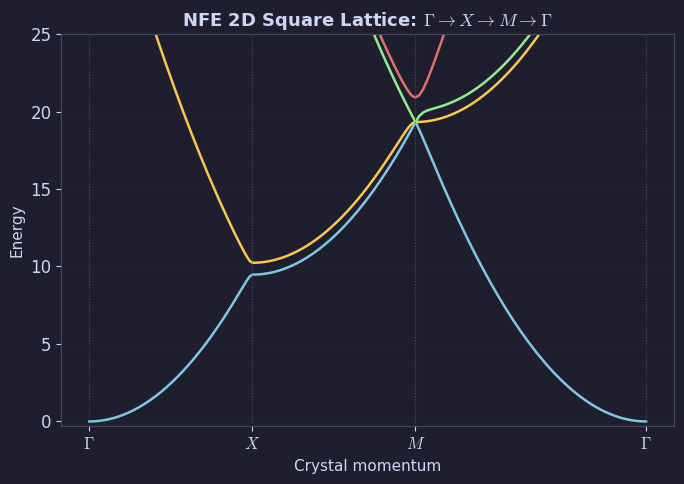

Fig 08 saved.


In [9]:

# Fig 08: Nearly-free electron 2D square lattice bands along G-X-M-G
a=1.; V1=0.4; h2m=1.
N_G = 3

def nfe_2d(kpath, nG=3):
    Gs = [(nx,ny) for nx in range(-nG,nG+1) for ny in range(-nG,nG+1)]
    Gv = np.array([(nx*2*np.pi/a, ny*2*np.pi/a) for nx,ny in Gs])
    bands = []
    for kx,ky in kpath:
        kv = np.array([kx,ky])
        H  = np.diag([h2m*np.dot(kv+g,kv+g) for g in Gv])
        for i in range(len(Gv)):
          for j in range(len(Gv)):
            n2 = int(round(np.linalg.norm(Gv[i]-Gv[j])*a/(2*np.pi)))
            if n2==1: H[i,j] += V1
        bands.append(np.sort(np.linalg.eigvalsh(H)))
    return np.array(bands)

N = 60
G = np.array([0.,0.]); X = np.array([np.pi/a,0.]); M = np.array([np.pi/a,np.pi/a])
p1 = [G+t*(X-G) for t in np.linspace(0,1,N)]
p2 = [X+t*(M-X) for t in np.linspace(0,1,N)]
p3 = [M+t*(G-M) for t in np.linspace(0,1,N)]
kpath = np.array(p1 + p2[1:] + p3[1:])
dist  = np.cumsum([0]+[np.linalg.norm(kpath[i+1]-kpath[i]) for i in range(len(kpath)-1)])
bands = nfe_2d(kpath, nG=N_G)

fig, ax = plt.subplots(figsize=(7,5))
cols = [BLUE,YELLOW,GREEN,RED,PURPLE,ORANGE,'#aaa']
for b in range(min(6,bands.shape[1])):
    ax.plot(dist, bands[:,b], color=cols[b], lw=1.8)
tick_pos = [0, dist[N-1], dist[2*N-2], dist[-1]]
tick_labs = [r'$\Gamma$',r'$X$',r'$M$',r'$\Gamma$']
for tp in tick_pos: ax.axvline(tp, color='#45475a', lw=.8, ls=':')
ax.set_xticks(tick_pos); ax.set_xticklabels(tick_labs, fontsize=12)
ax.set_xlabel('Crystal momentum',fontsize=11); ax.set_ylabel('Energy',fontsize=11)
ax.set_title(r'NFE 2D Square Lattice: $\Gamma\to X\to M\to\Gamma$', color='#cdd6f4')
ax.set_ylim(-0.3, 25); ax.grid(True, alpha=.2)
plt.tight_layout(); SAVE('fig08_nfe_3d.png'); plt.show()
print('Fig 08 saved.')


## Fig 09 — SC Tight-Binding Band Structure

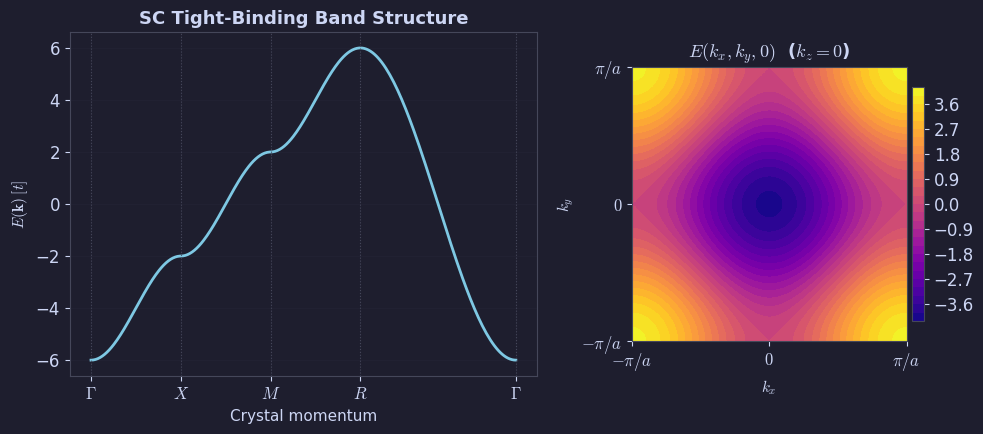

Fig 09 saved.


In [10]:

# Fig 09: 3D simple-cubic tight-binding along G-X-M-R-G
a=1.; t=1.; E0=0.
def E_sc(kx,ky,kz): return E0-2*t*(np.cos(kx*a)+np.cos(ky*a)+np.cos(kz*a))

N=80
G=np.array([0.,0.,0.]); X=np.array([np.pi/a,0.,0.])
M=np.array([np.pi/a,np.pi/a,0.]); R=np.array([np.pi/a,np.pi/a,np.pi/a])
segs = [(G,X),(X,M),(M,R),(R,G)]
k_all=[]; ticks=[0]
for s in segs:
    pts=[s[0]+tf*(s[1]-s[0]) for tf in np.linspace(0,1,N)]
    k_all.extend(pts); ticks.append(len(k_all)-1)
k_all=np.array(k_all)
E_all=E_sc(k_all[:,0],k_all[:,1],k_all[:,2])
dist=np.cumsum([0]+[np.linalg.norm(k_all[i+1]-k_all[i]) for i in range(len(k_all)-1)])

fig, axes = plt.subplots(1,2,figsize=(10,4.5),gridspec_kw={'width_ratios':[1.6,1]})

ax=axes[0]
ax.plot(dist, E_all, color=BLUE, lw=2.)
tick_pos=[dist[i] for i in ticks]
tick_labs=[r'$\Gamma$',r'$X$',r'$M$',r'$R$',r'$\Gamma$']
for tp in tick_pos: ax.axvline(tp, color='#45475a', lw=.8, ls=':')
ax.set_xticks(tick_pos); ax.set_xticklabels(tick_labs, fontsize=12)
ax.set_xlabel('Crystal momentum',fontsize=11)
ax.set_ylabel(r'$E(\mathbf{k})\;[t]$',fontsize=11)
ax.set_title('SC Tight-Binding Band Structure', color='#cdd6f4')
ax.grid(True, alpha=.2)

ax2=axes[1]
kv=np.linspace(-np.pi/a,np.pi/a,100)
KX,KY=np.meshgrid(kv,kv)
EE=E0-2*t*(np.cos(KX*a)+np.cos(KY*a))
cf=ax2.contourf(KX,KY,EE,levels=30,cmap='plasma')
ax2.set_aspect('equal')
ax2.set_xlabel(r'$k_x$',fontsize=11); ax2.set_ylabel(r'$k_y$',fontsize=11)
ax2.set_title(r'$E(k_x,k_y,0)$  ($k_z=0$)',color='#cdd6f4')
ax2.set_xticks([-np.pi/a,0,np.pi/a]); ax2.set_xticklabels([r'$-\pi/a$','$0$',r'$\pi/a$'])
ax2.set_yticks([-np.pi/a,0,np.pi/a]); ax2.set_yticklabels([r'$-\pi/a$','$0$',r'$\pi/a$'])
cb=fig.colorbar(cf,ax=ax2,fraction=.04,pad=.02)
cb.ax.yaxis.set_tick_params(color='#cdd6f4')
plt.setp(cb.ax.yaxis.get_ticklabels(), color='#cdd6f4')

plt.tight_layout(); SAVE('fig09_tb_3d_sc.png'); plt.show()
print('Fig 09 saved.')


## Fig 10 — Wannier Function vs Bloch State

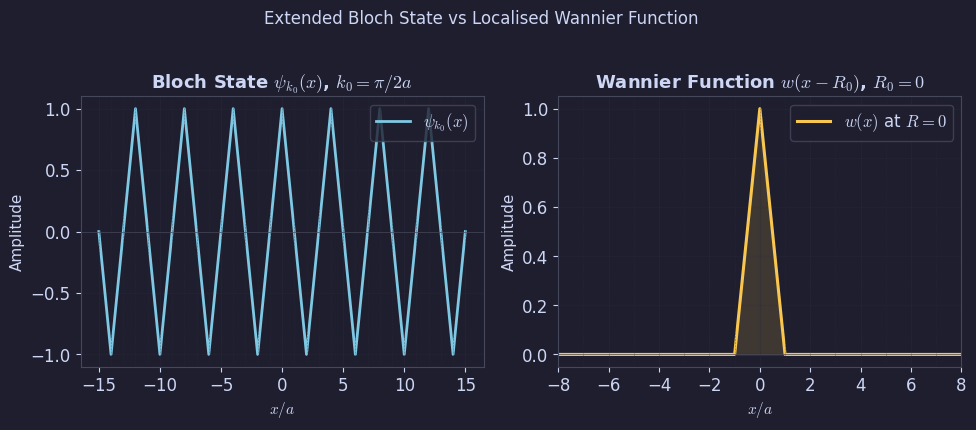

Fig 10 saved.


In [11]:

# Fig 10: Bloch state vs Wannier function (1D cosine band)
a=1.; N=200
k_arr = np.linspace(-np.pi/a, np.pi/a, N, endpoint=False)
x_latt = np.arange(-15,16)*a

# Bloch state at k=pi/(2a): psi_k(x) = e^{ikx}; take real part
k0 = np.pi/(2*a)
psi_bloch = np.cos(k0*x_latt)

# Wannier function at R=0: w(x) = (1/N) sum_k e^{ikx}
R0=0; amps = np.exp(-1j*k_arr*R0)/N
w_R0 = np.array([np.real(np.sum(amps*np.exp(1j*k_arr*x))) for x in x_latt])
w_R0 /= np.max(np.abs(w_R0))

fig, axes = plt.subplots(1,2,figsize=(10,4.2))

ax=axes[0]
ax.plot(x_latt/a, psi_bloch, color=BLUE, lw=2., label=r'$\psi_{k_0}(x)$')
ax.axhline(0, color='#45475a', lw=.5)
for xi in x_latt: ax.axvline(xi/a, color='#2a2a3e', lw=.4, ls=':')
ax.set_title(r'Bloch State $\psi_{k_0}(x)$, $k_0=\pi/2a$', color='#cdd6f4')
ax.set_xlabel(r'$x/a$',fontsize=11); ax.set_ylabel('Amplitude',fontsize=11)
ax.legend(facecolor=BG, edgecolor='#45475a', labelcolor='#cdd6f4')
ax.grid(True, alpha=.2)

ax=axes[1]
ax.plot(x_latt/a, w_R0, color=YELLOW, lw=2.2, label=r'$w(x)$ at $R=0$')
ax.fill_between(x_latt/a, 0, w_R0, alpha=.15, color=YELLOW)
ax.axhline(0, color='#45475a', lw=.5)
for xi in x_latt: ax.axvline(xi/a, color='#2a2a3e', lw=.4, ls=':')
ax.set_title(r'Wannier Function $w(x-R_0)$, $R_0=0$', color='#cdd6f4')
ax.set_xlabel(r'$x/a$',fontsize=11); ax.set_ylabel('Amplitude',fontsize=11)
ax.legend(facecolor=BG, edgecolor='#45475a', labelcolor='#cdd6f4')
ax.grid(True, alpha=.2); ax.set_xlim(-8,8)

plt.suptitle('Extended Bloch State vs Localised Wannier Function',
             color='#cdd6f4', fontsize=12, y=1.02)
plt.tight_layout(); SAVE('fig10_wannier.png'); plt.show()
print('Fig 10 saved.')


## Fig 11 — LCAO Bands

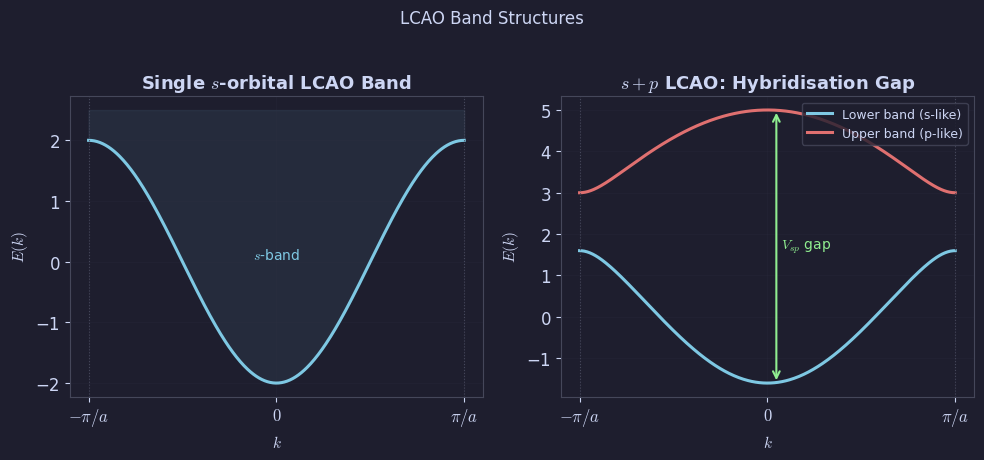

Fig 11 saved.


In [12]:

# Fig 11: LCAO — single s-band and s+p hybridisation gap
a=1.; k=np.linspace(-np.pi/a, np.pi/a, 400)

# Single s-band
Es0=0.; ts=1.
E_s = Es0 - 2*ts*np.cos(k*a)

# s+p model
Es=0.; Ep=4.; ts=0.8; tp=0.5; Vsp=1.2
E_lo=np.zeros_like(k); E_hi=np.zeros_like(k)
for i,ki in enumerate(k):
    H = np.array([[Es-2*ts*np.cos(ki*a),  1j*Vsp*np.sin(ki*a)],
                  [-1j*Vsp*np.sin(ki*a),  Ep+2*tp*np.cos(ki*a)]])
    ev = np.sort(np.real(np.linalg.eigvalsh(H)))
    E_lo[i]=ev[0]; E_hi[i]=ev[1]

fig, axes = plt.subplots(1,2,figsize=(10,4.5))

ax=axes[0]
ax.plot(k, E_s, color=BLUE, lw=2.2)
for xb in [-np.pi/a,np.pi/a]: ax.axvline(xb, color='#45475a', lw=.8, ls=':')
ax.fill_between(k, E_s, E_s.max()+.5, color=BLUE, alpha=.08)
ax.set_xticks([-np.pi/a,0,np.pi/a]); ax.set_xticklabels([r'$-\pi/a$','$0$',r'$\pi/a$'])
ax.set_xlabel(r'$k$',fontsize=11); ax.set_ylabel(r'$E(k)$',fontsize=11)
ax.set_title('Single $s$-orbital LCAO Band', color='#cdd6f4')
ax.text(0, Es0, r'$s$-band', color=BLUE, fontsize=10, ha='center', va='bottom')
ax.grid(True, alpha=.2)

ax=axes[1]
ax.plot(k, E_lo, color=BLUE, lw=2.2, label='Lower band (s-like)')
ax.plot(k, E_hi, color=RED,  lw=2.2, label='Upper band (p-like)')
for xb in [-np.pi/a,np.pi/a]: ax.axvline(xb, color='#45475a', lw=.8, ls=':')
idx0 = np.argmin(np.abs(k))
ax.annotate('', xy=(.15, E_hi[idx0]), xytext=(.15, E_lo[idx0]),
            arrowprops=dict(arrowstyle='<->', color=GREEN, lw=1.5))
ax.text(.22, (E_hi[idx0]+E_lo[idx0])/2, r'$V_{sp}$ gap',
        color=GREEN, fontsize=10, va='center')
ax.set_xticks([-np.pi/a,0,np.pi/a]); ax.set_xticklabels([r'$-\pi/a$','$0$',r'$\pi/a$'])
ax.set_xlabel(r'$k$',fontsize=11); ax.set_ylabel(r'$E(k)$',fontsize=11)
ax.set_title(r'$s+p$ LCAO: Hybridisation Gap', color='#cdd6f4')
ax.legend(facecolor=BG, edgecolor='#45475a', labelcolor='#cdd6f4', fontsize=9, loc='upper right')
ax.grid(True, alpha=.2)

plt.suptitle('LCAO Band Structures', color='#cdd6f4', fontsize=12, y=1.02)
plt.tight_layout(); SAVE('fig11_lcao_bands.png'); plt.show()
print('Fig 11 saved.')


---
## ZIP & Download

In [13]:

import shutil, os
z = shutil.make_archive('ch02_figures','zip','figures/ch02')
print(f'ZIP: {z}, {os.path.getsize(z)//1024} KB')
try:
    from google.colab import files
    files.download('ch02_figures.zip')
    print('Download triggered.')
except ImportError:
    print('Not in Colab — ch02_figures.zip in working directory.')


ZIP: /content/ch02_figures.zip, 808 KB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Download triggered.
